# 01 · OpenTME: download and processing

This notebook downloads the OpenTME tables (Galama et al., arXiv:2604.12075, 2026) and builds a **patient-level master table** of tissue features for one indication: all `tme` features that pass rule-based selection, plus selected features from the whole-tumour-region (`wtr_cell`, `wtr_tissue`) and tertiary-lymphoid-structure (`tls`) tables.

The indication and every parameter are read from the configuration (`configs/project.yaml`, `configs/analysis.yaml`, `configs/indications/<name>.yaml`). Breast cancer (TCGA-BRCA) is the pilot; running the notebook for another OpenTME cancer only requires a new indication file. Reusable code lives in `src/opentme_tcga/opentme.py`.

**Sections**
1. Data acquisition
2. Load and merge the five slide-level tables
3. Identifiers and slides per patient
4. Feature selection
5. Slide QC and one slide per patient
6. Derived features
7. Candidate master table
8. Exploratory analysis (completeness, composition, redundancy, vessel features)
9. Final master table

**Outputs**
- `<data>/interim/opentme_<opentme>_slides.parquet`: all five tables merged, one row per slide.
- `<data>/processed/opentme_<opentme>_patients.parquet`: master table, one slide per patient (input of notebook 03).
- `results/<indication>/01_opentme/` (tables) and `figures/<indication>/01_opentme/` (figures): QC audit.

## 0. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from opentme_tcga import opentme as otme
from opentme_tcga.config import ensure_dirs, load_config
from opentme_tcga.genomic_footprints import feature_family
from opentme_tcga.plotting import TLS_GROUP_COLORS

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", None)

In [2]:
INDICATION = "breast"          # name of a file in configs/indications/

cfg = load_config(INDICATION)
P = cfg["paths"]
PROC = cfg["opentme_processing"]
CANCER = cfg["indication"]["opentme"]     # OpenTME name of the indication

OUT_DIR = P["results"] / "01_opentme"          # tables
FIGS = P["figures"] / "01_opentme"             # figures
ensure_dirs(cfg)
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(parents=True, exist_ok=True)

print(f"Indication: {INDICATION} (OpenTME: {CANCER}, TCGA: {cfg['indication']['tcga_project']})")
print(f"Data folder: {P['data']}")
print(f"Results folder: {OUT_DIR.relative_to(P['root'])}")

Indication: breast (OpenTME: breast_cancer, TCGA: TCGA-BRCA)
Data folder: /Users/Admin/Desktop/GitHub/opentme-tcga-integration/data
Results folder: results/breast/01_opentme


## 1. Data acquisition

OpenTME is hosted on Hugging Face (gated, non-commercial licence; run `uv run hf auth login` once). For each cancer type it provides five slide-level tables, one row per diagnostic slide:

| Table | Content |
|---|---|
| `tme` | Whole-slide features: tissue QC, tissue segmentation, cell classification, cells in each tissue and cell neighbourhoods (~4,500 features) |
| `wtr_cell` | Cell features in the zones of the whole tumour region: tumour core, inner and outer invasive margin |
| `wtr_tissue` | Area and shape of these zones |
| `wtr_neighborhood` | Cell neighbourhood features in these zones |
| `tls` | Tertiary lymphoid structures: number, density, area and maturity |

The repository also holds the User Guide and the `settings/` files that define the feature names. Slide thumbnails are not downloaded. Set `DOWNLOAD = True` the first time; files already present are skipped.

In [3]:
DOWNLOAD = False

if DOWNLOAD:
    otme.download_opentme(P["raw_opentme"], cfg["opentme"]["repo_id"], cfg["opentme"]["allow_patterns"],
                          revision=cfg["opentme"].get("revision"))

inventory = otme.list_tables(P["raw_opentme"])
print(f"{len(inventory)} tables found for {inventory['cancer'].nunique()} cancer types")
inventory.pivot(index="cancer", columns="group", values="path").notna()

40 tables found for 8 cancer types


group,tls,tme,wtr_cell,wtr_neighborhood,wtr_tissue
cancer,,,,,
bladder_cancer,True,True,True,True,True
breast_cancer,True,True,True,True,True
colorectal_cancer,True,True,True,True,True
liver_cancer,True,True,True,True,True
lung_cancer,True,True,True,True,True
pancreatic_cancer,True,True,True,True,True
prostate_cancer,True,True,True,True,True
stomach_cancer,True,True,True,True,True


## 2. Load and merge the five slide-level tables

Each table is checked for the identifier columns and for duplicated slides; then we verify that all five tables contain exactly the same slides and merge them one-to-one on `TCGA_FILE_NAME`. `ABSOLUTE_AREA` exists in two tables with different meanings (whole tissue in `tme`, whole tumour region in `wtr_tissue`), so the second one is renamed before merging (`renames` in the configuration).

In [4]:
tables = otme.load_indication_tables(inventory, CANCER)
for group, df in tables.items():
    print(f"{group:18s} {df.shape[0]:5d} slides  {df.shape[1] - len(otme.ID_COLS):5d} features")

otme.check_same_slides(tables)

tme                 1125 slides   4544 features
wtr_cell            1125 slides   2208 features
wtr_tissue          1125 slides    449 features
wtr_neighborhood    1125 slides   4230 features
tls                 1125 slides   1310 features


,n_slides,only_here,missing_here
table,,,
tme,1125,0,0
wtr_cell,1125,0,0
wtr_tissue,1125,0,0
wtr_neighborhood,1125,0,0
tls,1125,0,0


In [5]:
slides, feature_source = otme.merge_slide_tables(tables, renames=PROC["renames"])
del tables

print(f"{CANCER}: {slides.shape[0]} slides x {len(feature_source)} features")
feature_source.value_counts().to_frame("n_features")

breast_cancer: 1125 slides x 12741 features


,n_features
table,
tme,4544
wtr_neighborhood,4230
wtr_cell,2208
tls,1310
wtr_tissue,449


## 3. Identifiers and slides per patient

TCGA barcodes encode the patient (first 12 characters) and the sample type (characters 14–15: `01` primary solid tumour, `06` metastasis, `11` normal tissue). We check that `TCGA_CASE_ID` matches the barcode, tabulate sample types and count the patients with more than one slide.

In [6]:
slides["SAMPLE_TYPE"] = otme.sample_type(slides[otme.SLIDE_KEY])
concordant = (otme.patient_id(slides[otme.SLIDE_KEY]) == slides[otme.PATIENT_KEY]).all()
print(f"TCGA_CASE_ID matches the 12-character barcode for all slides: {concordant}")
print("Sample types:", slides["SAMPLE_TYPE"].value_counts().to_dict())

n_slides = otme.slides_per_patient(slides)
n_multi = int((n_slides > 1).sum())
print(f"{len(n_slides)} patients; {n_multi} have more than one slide ({n_multi / len(n_slides):.1%})")
n_slides.value_counts().sort_index().rename("n_patients").to_frame()

TCGA_CASE_ID matches the 12-character barcode for all slides: True
Sample types: {'01': 1124, '06': 1}
1054 patients; 66 have more than one slide (6.3%)


,n_patients
n_slides,
1,988
2,62
3,3
4,1


Numeric features are stored as `float32` (half the memory, no practical loss of precision) and the merged slide-level table is saved, together with the table of origin of each feature.

In [7]:
numeric, non_numeric = otme.split_numeric(slides, feature_source.index.tolist())
print("Non-numeric features:", non_numeric)

slides = otme.downcast_features(slides, numeric)
slides.to_parquet(P["opentme_slides"], index=False)
feature_source.reset_index().to_csv(OUT_DIR / "feature_source.csv", index=False)
print(f"Saved {P['opentme_slides'].name} ({P['opentme_slides'].stat().st_size / 1e6:.1f} MB)")

Non-numeric features: ['CELL_CLASSES']
Saved opentme_breast_cancer_slides.parquet (66.6 MB)


## 4. Feature selection

Feature names follow a template grammar defined in `settings/tme_features.yaml`, filled with the classes of the Atlas H&E-TME models listed in `settings/model_variables.yaml` (see [TME Studio, tutorial 2](https://github.com/aignostics/tme-studio) and the [OpenTME User Guide](https://huggingface.co/datasets/Aignostics/OpenTME/blob/main/user_guide.pdf)). This lets us select features by rules on their names, before looking at any value.

### 4.1 `tme` features

Rules applied in order (`tme_exclusions` in the configuration):
- **Tissues and cell types not studied:** blood, normal epithelium (tissue and cells) and unclassified tissue (`Other`).
- **Image-quality classes** (`qc_cls`: out of focus, tissue artifact, marker): used for slide QC in section 5, not as biological features.
- **40 µm neighbourhoods:** largely redundant with the 20 µm ones.
- **Redundant shape descriptors:** largest region (sensitive to how the tissue was cut), roundness, perimeter and axis lengths; area and eccentricity are kept.

Counts and absolute areas are kept here: they depend on the amount of tissue but are needed as denominators and are filtered later, in each analysis.

In [8]:
model_variables = otme.load_model_variables(P["raw_opentme"])
for key, values in model_variables.items():
    print(f"{key}: {values}")

tme_rules = otme.build_tme_exclusions(PROC["tme_exclusions"], model_variables)
tme_all = [f for f in otme.search_features(feature_source, table="tme") if f in numeric]
tme_selected, tme_log = otme.apply_exclusions(tme_all, tme_rules)
tme_log

qc_cls: ['Valid Tissue', 'Marker', 'Out Of Focus', 'Tissue Artifact']
tissue_cls: ['Carcinoma', 'Stroma', 'Necrosis', 'Blood', 'Vessel', 'Epithelial tissue', 'Other']
cell_cls: ['Carcinoma cell', 'Lymphocyte', 'Macrophage', 'Granulocyte', 'Plasma cell', 'Epithelial cell', 'Endothelial cell', 'Fibroblast', 'Other']
radius: [20, 40]


,step,n_removed,n_left
0,Start,0,4543
1,Exclude Tissues and cell types not studied,2804,1739
2,Exclude Model classes 'qc_cls',8,1731
3,Exclude 40 µm neighbourhood,777,954
4,Exclude Redundant shape descriptors,48,906


### 4.2 `tls` and `wtr` features

- **Tertiary lymphoid structures (`tls`):** ectopic lymph-node-like aggregates of T and B cells; mature TLS (with germinal centres) mark an effective adaptive response. Of the many per-structure shape metrics we keep only the summary features: count, density and area by maturity.
- **Whole tumour region (`wtr_cell`, `wtr_tissue`):** the tumour core and the invasive margin (1 mm on each side of the tumour border). Lymphocyte densities by zone distinguish lymphocytes that reach the tumour core from those that stay at the border. We keep the zone lymphocyte densities (excluding blood, necrosis, normal epithelium and other tissue, as in 4.1) and the tumour-core area.
- **`wtr_neighborhood`:** not used; cell proximity is already described at 20 µm in `tme`.

In [9]:
tls_features = otme.select_tls_features(feature_source, PROC["tls"]["prefixes"])
wtr = PROC["wtr"]
wtr_features = otme.select_wtr_features(feature_source, wtr["table"], wtr["include_keywords"],
                                        wtr["exclude_keywords"], wtr["extra_features"])

print(f"tme: {len(tme_selected)} features")
print(f"tls: {len(tls_features)} features: {tls_features}")
print(f"wtr: {len(wtr_features)} features")
candidate_features = list(dict.fromkeys(tme_selected + tls_features + wtr_features))
print(f"Candidate features: {len(candidate_features)}")

tme: 906 features
tls: 6 features: ['AREA_TLS_IMMATURE', 'AREA_TLS_MATURE', 'COUNT_TLS_IMMATURE', 'COUNT_TLS_MATURE', 'DENSITY_TLS_IMMATURE', 'DENSITY_TLS_MATURE']
wtr: 17 features
Candidate features: 929


## 5. Slide QC and one slide per patient

Atlas H&E-TME already removes low-quality regions within each slide, so every feature is computed on valid tissue only. Here we exclude **whole slides** (`slide_qc` in the configuration):
1. **Primary tumour only:** sample type `01`.
2. **Enough carcinoma:** carcinoma area ≥ the minimum (2 mm² for breast), so that densities are estimated on enough tissue. The threshold was chosen from the distribution below.
3. **Image quality:** at most 50% of the tissue unusable (out of focus + tissue artifact + pen marker).

In [10]:
qc_cfg = PROC["slide_qc"]
qc = otme.slide_qc(
    slides,
    area_feature=qc_cfg["area_feature"],
    min_carcinoma_area_mm2=qc_cfg["min_carcinoma_area_mm2"],
    unusable_features=qc_cfg["unusable_features"],
    max_unusable_fraction=qc_cfg["max_unusable_fraction"],
    sample_types=qc_cfg["sample_types"],
)
print(qc[["carcinoma_area_mm2", "unusable_fraction"]].describe().round(3))
print("\nSlides failing each criterion:")
print((~qc[["primary_tumor", "enough_carcinoma", "good_quality"]]).sum().to_string())
print(f"\nSlides passing QC: {qc['qc_pass'].sum()} / {len(qc)}")

       carcinoma_area_mm2  unusable_fraction
count            1125.000           1125.000
mean               41.045              0.028
std                35.083              0.073
min                 0.000              0.000
25%                15.148              0.003
50%                31.600              0.008
75%                57.273              0.022
max               231.506              0.941

Slides failing each criterion:
primary_tumor        1
enough_carcinoma    31
good_quality         6

Slides passing QC: 1089 / 1125


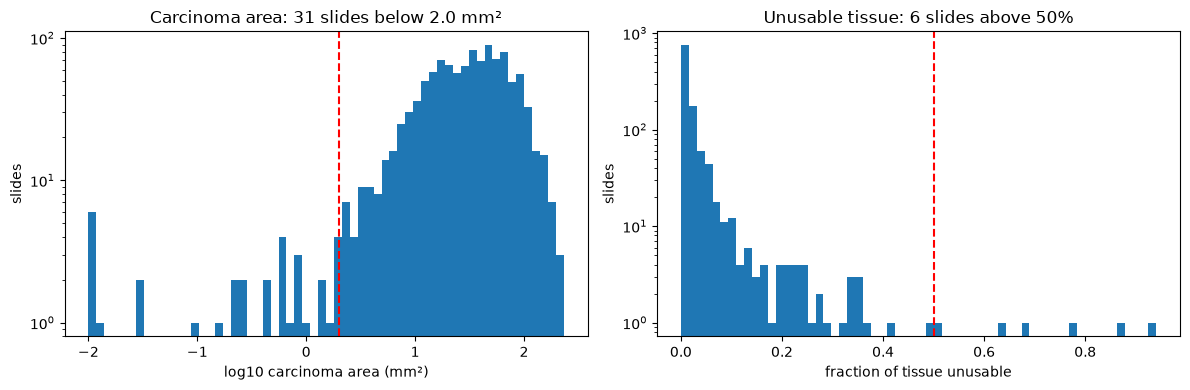

In [11]:
min_area, max_unusable = qc_cfg["min_carcinoma_area_mm2"], qc_cfg["max_unusable_fraction"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

n_small = int((qc["carcinoma_area_mm2"] < min_area).sum())
axes[0].hist(np.log10(qc["carcinoma_area_mm2"].clip(lower=0.01)), bins=60)
axes[0].axvline(np.log10(min_area), color="red", ls="--")
axes[0].set(xlabel="log10 carcinoma area (mm²)", ylabel="slides", yscale="log",
            title=f"Carcinoma area: {n_small} slides below {min_area} mm²")

n_unusable = int((qc["unusable_fraction"] > max_unusable).sum())
axes[1].hist(qc["unusable_fraction"], bins=60)
axes[1].axvline(max_unusable, color="red", ls="--")
axes[1].set(xlabel="fraction of tissue unusable", ylabel="slides", yscale="log",
            title=f"Unusable tissue: {n_unusable} slides above {max_unusable:.0%}")

fig.tight_layout()
fig.savefig(FIGS / "qc_distributions.png", dpi=150)
plt.show()

How many slides would other thresholds exclude?

In [12]:
sens = qc_cfg["sensitivity"]
display(otme.qc_sensitivity(qc["carcinoma_area_mm2"], sens["min_carcinoma_area_mm2"], fails_below=True)
        .rename(columns={"threshold": "min carcinoma area (mm²)"}))
display(otme.qc_sensitivity(qc["unusable_fraction"], sens["max_unusable_fraction"], fails_below=False)
        .rename(columns={"threshold": "max unusable fraction"}))

,min carcinoma area (mm²),slides_excluded
0,0.5,17
1,1.0,26
2,2.0,31
3,5.0,72


,max unusable fraction,slides_excluded
0,0.2,32
1,0.3,16
2,0.5,6
3,0.7,3


For patients with several slides passing QC, we keep the slide with the largest carcinoma area. `N_SLIDES_TOTAL` is stored so that analyses can be repeated without these patients. The QC log (one row per slide, with pass/fail flags and whether it was selected) is saved.

In [13]:
selected = otme.one_slide_per_patient(slides, qc["qc_pass"], by=PROC["slide_selection_feature"])

qc["selected"] = qc[otme.SLIDE_KEY].isin(selected[otme.SLIDE_KEY])
qc.to_csv(OUT_DIR / "slide_selection.csv", index=False)

n_multi_kept = int((selected["N_SLIDES_TOTAL"] > 1).sum())
print(f"{len(selected)} patients after QC; {n_multi_kept} had more than one slide")

1030 patients after QC; 65 had more than one slide


## 6. Derived features

- **TLS missing values:** slides without TLS have missing values in the `tls` table (counts are never 0), so missing means absence and is set to 0.
- **Ratios** (unit-free, NaN when the denominator is 0):
  - `DERIVED_LYMPHOCYTE_INFILTRATION_INDEX` = lymphocyte density in carcinoma / in stroma (whole slide, `tme`);
  - `DERIVED_LYMPHOCYTE_CORE_MARGIN_INDEX` = lymphocyte density in the tumour core / in the outer invasive margin (`wtr_cell`).
- **TLS presence:** `DERIVED_TLS_PRESENT` (any TLS) and `DERIVED_MATURE_TLS_PRESENT` (mature TLS).

Immune phenotypes (inflamed / excluded) are defined in notebook 04, on hot tumours only, from these densities.

In [14]:
if PROC["tls"]["fill_missing_with_zero"]:
    selected[tls_features] = selected[tls_features].fillna(0)

selected, derived_features = otme.add_derived_features(selected, PROC["derived"]["ratios"],
                                                       PROC["derived"]["presence"])
selected[derived_features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
DERIVED_LYMPHOCYTE_INFILTRATION_INDEX,1030.0,0.330,0.379,0.016,0.115,0.220,0.413,4.885
DERIVED_LYMPHOCYTE_CORE_MARGIN_INDEX,1030.0,1.091,1.148,0.021,0.379,0.739,1.404,16.160
DERIVED_TLS_PRESENT,1030.0,0.831,0.375,0.000,1.000,1.000,1.000,1.000
DERIVED_MATURE_TLS_PRESENT,1030.0,0.204,0.403,0.000,0.000,0.000,0.000,1.000


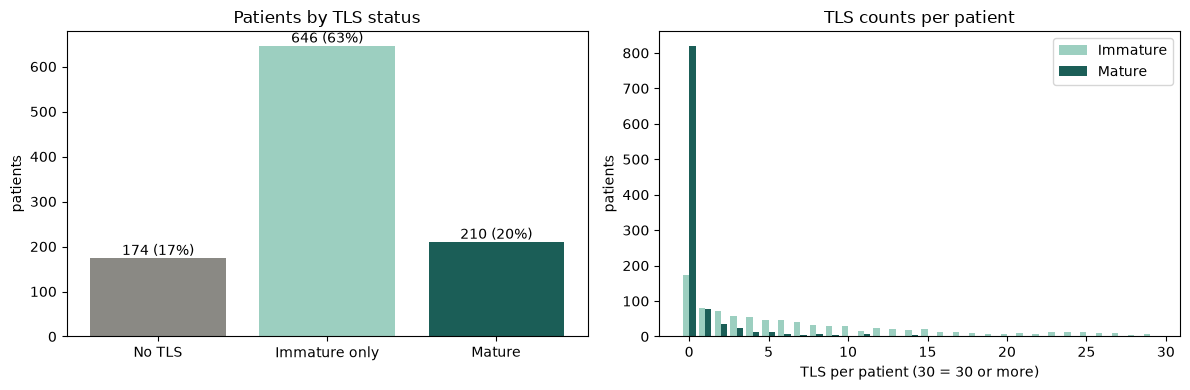

In [15]:
mature = selected["COUNT_TLS_MATURE"]
immature = selected["COUNT_TLS_IMMATURE"]
groups = list(TLS_GROUP_COLORS)                     # No TLS, Immature only, Mature
status = pd.Series(np.select([mature > 0, immature > 0], groups[:0:-1], default=groups[0]), index=selected.index)
counts = status.value_counts().reindex(groups, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(counts.index, counts.values, color=[TLS_GROUP_COLORS[g] for g in groups])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v} ({v / len(status):.0%})", ha="center", va="bottom")
axes[0].set(ylabel="patients", title="Patients by TLS status")

bins = np.arange(0, 31) - 0.5
axes[1].hist([immature.clip(upper=30), mature.clip(upper=30)], bins=bins,
             label=["Immature", "Mature"],
             color=[TLS_GROUP_COLORS["Immature only"], TLS_GROUP_COLORS["Mature"]])
axes[1].set(xlabel="TLS per patient (30 = 30 or more)", ylabel="patients", title="TLS counts per patient")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGS / "tls_overview.png", dpi=150)
plt.show()

Most tumours contain TLS, mainly immature aggregates; mature TLS with germinal centres are much rarer and their counts are zero-inflated, which is why they are also encoded as a presence flag.

## 7. Candidate master table

Identifiers, `N_SLIDES_TOTAL`, the candidate features of section 4 that are not empty or constant in the patients kept, and the derived features. This table still contains the vessel features, which are inspected in section 8.5 before the final master table is saved in section 9.

In [16]:
features_keep = otme.non_constant(selected, candidate_features)
print(f"Candidate features: {len(candidate_features)}; "
      f"{len(candidate_features) - len(features_keep)} empty or constant dropped; {len(features_keep)} kept")

columns = list(dict.fromkeys(otme.ID_COLS + ["N_SLIDES_TOTAL"] + features_keep + derived_features))
master = selected[columns].reset_index(drop=True)
features = features_keep + derived_features
print(f"Candidate master table: {master.shape[0]} patients x {master.shape[1]} columns")
print(pd.Series(features).map(feature_source).fillna("derived").value_counts().to_string())

Candidate features: 929; 12 empty or constant dropped; 917 kept
Candidate master table: 1030 patients x 927 columns
tme           906
tls             6
wtr_cell        4
derived         4
wtr_tissue      1


## 8. Exploratory analysis

A hypothesis-free description of the master table, using OpenTME data only.

### 8.1 Units of density features

Densities are converted to cells (or structures) per mm² with the factors in `density_per_mm2` (`configs/project.yaml`): `tme` is per µm² (Galama et al. 2026), `wtr_cell` per mm². The unit of TLS densities is not documented; we assume per mm², as the smallest non-zero value corresponds to one TLS per slide. Check: lymphocyte densities from `tme` and `wtr_cell` should have the same order of magnitude.

In [17]:
factors = cfg["density_per_mm2"]
check = {
    "CELL_DENSITY_LYMPHOCYTE_IN_CARCINOMA": "tme",
    "CELL_DENSITY_LYMPHOCYTE_IN_TUMOR_CORE": "wtr_cell",
    "DENSITY_TLS_MATURE": "tls",
    "DENSITY_TLS_IMMATURE": "tls",
}
units = pd.DataFrame({
    "table": check,
    "median_raw": {f: master[f].median() for f in check},
    "median_per_mm2": {f: otme.density_per_mm2(master[f], t, factors).median() for f, t in check.items()},
    "min_nonzero_per_mm2": {f: otme.density_per_mm2(master.loc[master[f] > 0, f], t, factors).min()
                            for f, t in check.items()},
})
display(units)

lymph = units.loc[["CELL_DENSITY_LYMPHOCYTE_IN_CARCINOMA", "CELL_DENSITY_LYMPHOCYTE_IN_TUMOR_CORE"], "median_per_mm2"]
ratio = lymph.iloc[0] / lymph.iloc[1]
print(f"Carcinoma / tumour-core median after conversion: {ratio:.2f} "
      f"({'consistent' if 0.1 < ratio < 10 else 'CHECK THE UNIT FACTORS'})")

,table,median_raw,median_per_mm2,min_nonzero_per_mm2
CELL_DENSITY_LYMPHOCYTE_IN_CARCINOMA,tme,0.000131,131.049988,4.296000
CELL_DENSITY_LYMPHOCYTE_IN_TUMOR_CORE,wtr_cell,323.682190,323.682190,11.109424
DENSITY_TLS_MATURE,tls,0.000000,0.000000,0.001800
DENSITY_TLS_IMMATURE,tls,0.030587,0.030587,0.002119


Carcinoma / tumour-core median after conversion: 0.40 (consistent)


### 8.2 Completeness

In [18]:
eda = PROC["eda"]
comp = otme.completeness(master, features, feature_source)
comp.to_csv(OUT_DIR / "completeness.csv")
otme.completeness_by_table(comp, eda["missing_flag"], eda["zero_flag"]).round(3)

,n_features,median_missing,n_missing_flagged,n_zero_flagged
table,,,,
derived,4,0.0,0,1
tls,6,0.0,0,3
tme,906,0.0,6,2
wtr_cell,4,0.0,0,0
wtr_tissue,1,0.0,0,0


In [19]:
print(f"Features with more than {eda['missing_flag']:.0%} missing values:")
display(comp[comp["frac_missing"] > eda["missing_flag"]].sort_values("frac_missing", ascending=False))
high_zero = comp[comp["frac_zero"] > eda["zero_flag"]]
print(f"\nFeatures with more than {eda['zero_flag']:.0%} zeros: {len(high_zero)}")
display(high_zero.sort_values("frac_zero", ascending=False).head(15))

Features with more than 20% missing values:


,table,frac_missing,frac_zero
AVG_MIN_DISTANCE_OF_PLASMA_CELLS_AROUND_CARCINOMA_CELL_IN_VESSEL_20,tme,0.519417,0.0
AVG_MIN_DISTANCE_OF_CARCINOMA_CELLS_AROUND_PLASMA_CELL_IN_VESSEL_20,tme,0.484466,0.0
AVG_MIN_DISTANCE_OF_CARCINOMA_CELLS_AROUND_MACROPHAGE_IN_VESSEL_20,tme,0.391262,0.0
AVG_MIN_DISTANCE_OF_MACROPHAGES_AROUND_CARCINOMA_CELL_IN_VESSEL_20,tme,0.384466,0.0
AVG_MIN_DISTANCE_OF_GRANULOCYTES_AROUND_CARCINOMA_CELL_IN_VESSEL_20,tme,0.351456,0.0
AVG_MIN_DISTANCE_OF_PLASMA_CELLS_AROUND_MACROPHAGE_IN_VESSEL_20,tme,0.236893,0.0



Features with more than 50% zeros: 6


,table,frac_missing,frac_zero
AREA_TLS_MATURE,tls,0.0,0.796117
COUNT_TLS_MATURE,tls,0.0,0.796117
DENSITY_TLS_MATURE,tls,0.0,0.796117
DERIVED_MATURE_TLS_PRESENT,derived,0.0,0.796117
NUMBER_OF_CELLS_WITH_PLASMA_CELL_NEIGHBORS_AROUND_CARCINOMA_CELL_IN_VESSEL_20,tme,0.0,0.519417
NUMBER_OF_PLASMA_CELLS_AROUND_CARCINOMA_CELL_IN_VESSEL_20,tme,0.0,0.519417


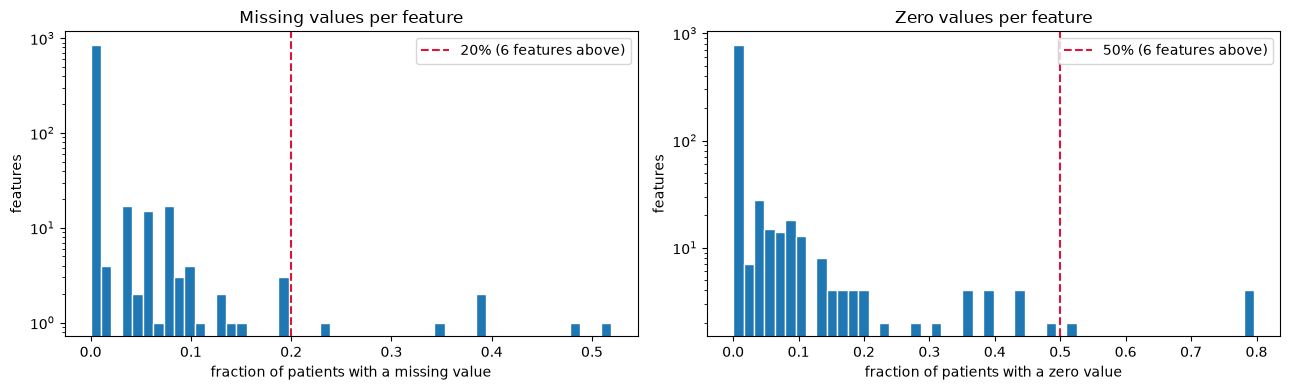

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, flag, label in [(axes[0], "frac_missing", eda["missing_flag"], "missing"),
                             (axes[1], "frac_zero", eda["zero_flag"], "zero")]:
    n_flag = int((comp[col] > flag).sum())
    ax.hist(comp[col], bins=50, color="tab:blue", edgecolor="white")
    ax.axvline(flag, color="crimson", ls="--", label=f"{flag:.0%} ({n_flag} features above)")
    ax.set(xlabel=f"fraction of patients with a {label} value", ylabel="features", yscale="log",
           title=f"{label.capitalize()} values per feature")
    ax.legend()
fig.tight_layout()
fig.savefig(FIGS / "completeness.png", dpi=150)
plt.show()

### 8.3 Cohort composition

Relative area of each tissue class (% of valid tissue) and percentage of each cell type among all detected cells.

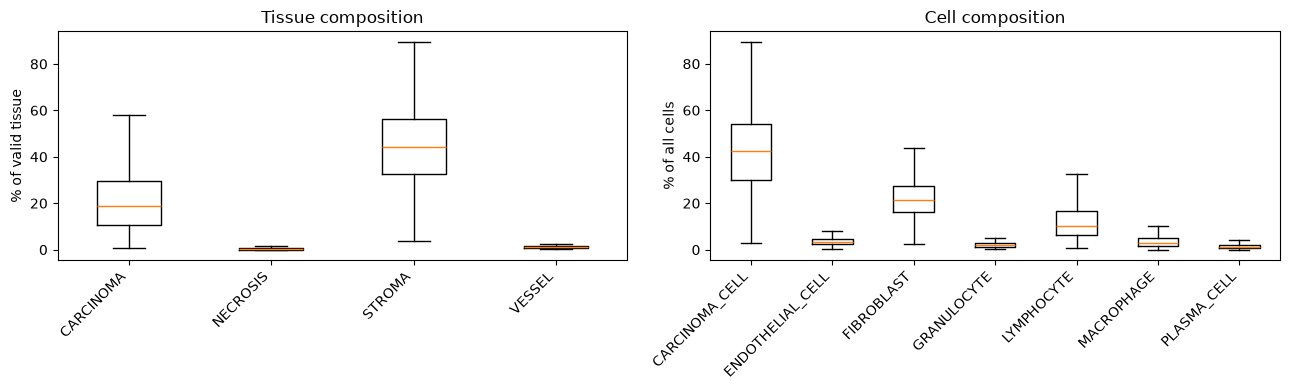

,median
RELATIVE_AREA_CARCINOMA,18.799999
RELATIVE_AREA_NECROSIS,0.100000
RELATIVE_AREA_STROMA,44.299999
RELATIVE_AREA_VESSEL,1.100000
CELL_PERCENTAGE_CARCINOMA_CELL,42.599998
CELL_PERCENTAGE_ENDOTHELIAL_CELL,3.300000
CELL_PERCENTAGE_FIBROBLAST,21.200001
CELL_PERCENTAGE_GRANULOCYTE,1.900000
CELL_PERCENTAGE_LYMPHOCYTE,10.100000
CELL_PERCENTAGE_MACROPHAGE,2.900000


In [21]:
tissue_cols = [c for c in master.columns if c.startswith("RELATIVE_AREA_")]
cell_cols = [c for c in master.columns if c.startswith("CELL_PERCENTAGE_") and "_IN_" not in c]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, cols, prefix, ylabel, title in [
    (axes[0], tissue_cols, "RELATIVE_AREA_", "% of valid tissue", "Tissue composition"),
    (axes[1], cell_cols, "CELL_PERCENTAGE_", "% of all cells", "Cell composition"),
]:
    ax.boxplot([master[c].dropna() for c in cols], showfliers=False)
    ax.set_xticks(range(1, len(cols) + 1), [c.removeprefix(prefix) for c in cols], rotation=45, ha="right")
    ax.set(ylabel=ylabel, title=title)
fig.tight_layout()
fig.savefig(FIGS / "composition.png", dpi=150)
plt.show()

master[tissue_cols + cell_cols].median().round(1).rename("median").to_frame()

### 8.4 Redundancy

Pairwise Spearman correlations between all numeric features: how many features have a near-duplicate, and how much of this is due to size-dependent features (counts and absolute areas, which all scale with the amount of tissue).

921 numeric features, 848,241 pairs
  pairs with |rho| > 0.80: 7,836 (0.92%)
  pairs with |rho| > 0.90: 2,367 (0.28%)
  pairs with |rho| > 0.95: 873 (0.10%)

Features with a near-duplicate (max |rho| > 0.95):
  all features:                480 of 921 (52.1%)
  without counts and areas:    114 of 567 (20.1%)


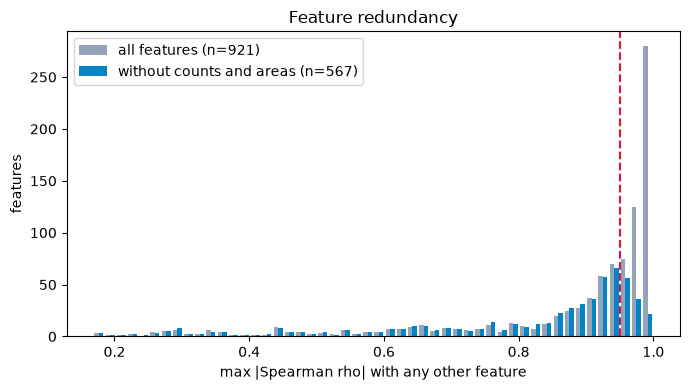

In [22]:
num_features = master[features].select_dtypes("number").columns.tolist()
max_rho, pairs = otme.max_abs_spearman(master, num_features)
print(f"{len(num_features)} numeric features, {len(pairs):,} pairs")
for t in eda["redundancy_thresholds"]:
    print(f"  pairs with |rho| > {t:.2f}: {(pairs > t).sum():,} ({(pairs > t).mean():.2%})")

relative = [f for f in num_features if not any(w in f for w in eda["size_keywords"])]
max_rho_rel, _ = otme.max_abs_spearman(master, relative)
top = max(eda["redundancy_thresholds"])
print(f"\nFeatures with a near-duplicate (max |rho| > {top}):")
print(f"  all features:               {(max_rho > top).sum():4d} of {len(max_rho)} ({(max_rho > top).mean():.1%})")
print(f"  without counts and areas:   {(max_rho_rel > top).sum():4d} of {len(max_rho_rel)} ({(max_rho_rel > top).mean():.1%})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist([max_rho, max_rho_rel], bins=50, color=["#94a3b8", "#0284c7"],
        label=[f"all features (n={len(max_rho)})", f"without counts and areas (n={len(max_rho_rel)})"])
ax.axvline(top, color="crimson", ls="--")
ax.set(xlabel="max |Spearman rho| with any other feature", ylabel="features", title="Feature redundancy")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGS / "redundancy.png", dpi=150)
plt.show()

Much of the redundancy comes from size-dependent features. The master table keeps all of them as a reference; each analysis then restricts itself to intensive features (densities, percentages, ratios) and applies its own redundancy filter (notebooks 06 and 07).

### 8.5 Vessel features

`Vessel` is a tissue class of Atlas H&E-TME covering all vascular structures. It was kept in section 4 because vascular architecture can matter for immune exclusion. During modelling (notebook 07), however, features measured *inside* vessel tissue appeared among the most important predictors of PAM50 subtype without a clear biological explanation. These are the neighbourhood features `..._IN_VESSEL_20` and the cell densities or percentages `..._IN_VESSEL` (`quality_exclusions` in the configuration). Vessel tissue itself (`RELATIVE_AREA_VESSEL`, shape) and distances to vessels are not affected. We inspect them here, where they enter the pipeline:

1. How much tissue is vessel?
2. Are these features sparser than the others (zero or missing)?
3. Do they track vessel area and overall immune infiltration rather than a property of the vessels?

In [23]:
vq = PROC["quality_exclusions"]["vessel"]
vessel_features = otme.match_pattern(features, vq["substrings"], vq["suffixes"])
other_features = [f for f in num_features if f not in vessel_features]

print(f"Vessel features in the candidate master table: {len(vessel_features)}")
display(pd.Series([feature_family(f) for f in vessel_features]).value_counts().rename("n_features").to_frame())

area = master[vq["reference_area"]]
print(f"{vq['reference_area']}: median {area.median():.2f}% of tissue "
      f"(IQR {area.quantile(0.25):.2f}–{area.quantile(0.75):.2f}%)")

Vessel features in the candidate master table: 280


,n_features
neighbourhood: carcinoma cell,35
neighbourhood: endothelial cell,35
neighbourhood: fibroblast,35
neighbourhood: granulocyte,35
neighbourhood: lymphocyte,35
neighbourhood: macrophage,35
neighbourhood: plasma cell,35
neighbourhood: vessel,12
cell density / composition: carcinoma cell,3
cell density / composition: endothelial cell,3


RELATIVE_AREA_VESSEL: median 1.11% of tissue (IQR 0.80–1.51%)


In [24]:
sparsity = pd.DataFrame({
    "vessel": otme.zero_or_missing(master, vessel_features).describe(),
    "other": otme.zero_or_missing(master, other_features).describe(),
}).T[["count", "25%", "50%", "75%"]]
print("Fraction of patients with a zero or missing value, per feature:")
display(sparsity.round(3))

corr = pd.concat([
    otme.spearman_with(master, vessel_features, vq["reference_area"]),
    otme.spearman_with(master, vessel_features, vq["reference_immune"]),
], axis=1)
corr["zero_or_missing"] = otme.zero_or_missing(master, vessel_features)
corr.to_csv(OUT_DIR / "vessel_features.csv")
print("Spearman correlation of vessel features with vessel area and overall lymphocyte density:")
display(corr.abs().describe().loc[["count", "25%", "50%", "75%", "max"]].round(2))

Fraction of patients with a zero or missing value, per feature:


,count,25%,50%,75%
vessel,280.0,0.003,0.045,0.103
other,641.0,0.000,0.000,0.001


Spearman correlation of vessel features with vessel area and overall lymphocyte density:


,rho_RELATIVE_AREA_VESSEL,rho_CELL_DENSITY_LYMPHOCYTE,zero_or_missing
count,280.00,280.00,280.00
25%,0.06,0.07,0.00
50%,0.13,0.15,0.04
75%,0.46,0.27,0.10
max,0.64,0.89,0.52


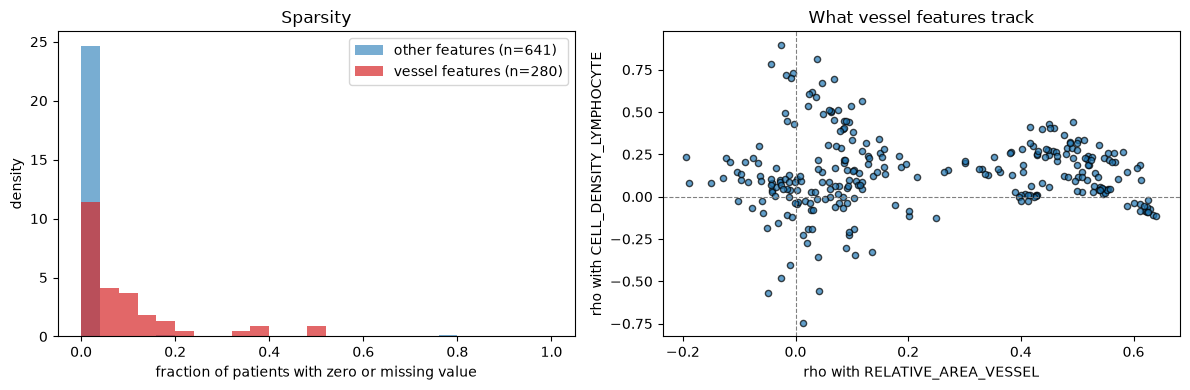

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0, 1, 26)
axes[0].hist(otme.zero_or_missing(master, other_features), bins=bins, alpha=0.6, density=True,
             label=f"other features (n={len(other_features)})")
axes[0].hist(corr["zero_or_missing"], bins=bins, alpha=0.7, density=True, color="#d62728",
             label=f"vessel features (n={len(vessel_features)})")
axes[0].set(xlabel="fraction of patients with zero or missing value", ylabel="density", title="Sparsity")
axes[0].legend()

r_area, r_imm = corr.columns[:2]
axes[1].scatter(corr[r_area], corr[r_imm], s=20, alpha=0.7, edgecolors="k")
axes[1].axhline(0, color="grey", lw=0.8, ls="--")
axes[1].axvline(0, color="grey", lw=0.8, ls="--")
axes[1].set(xlabel=f"rho with {vq['reference_area']}", ylabel=f"rho with {vq['reference_immune']}",
            title="What vessel features track")
fig.tight_layout()
fig.savefig(FIGS / "vessel_features.png", dpi=150)
plt.show()

**Decision.** Vessel tissue covers a small fraction of each slide, so features measured inside vessels are estimated on little tissue. They are more often zero or missing than other features, and they mainly track either the amount of vessel on the slide or overall lymphocyte infiltration, rather than a property of the vessels themselves. When they were included, several of them ranked among the top predictors of PAM50 subtype without a clear biological explanation, and removing them did not reduce predictive performance (notebook 07). They are therefore removed from the master table (`quality_exclusions` in `configs/analysis.yaml`, where the rationale is recorded). Vessel tissue features (area, shape), distances to vessels and endothelial-cell features are kept. 

## 9. Final master table

Remove the features flagged in `quality_exclusions` and save the patient-level master table, the input of notebook 03.

In [26]:
excluded = []
for name, rule in PROC["quality_exclusions"].items():
    found = otme.match_pattern(master.columns.tolist(), rule.get("substrings", []), rule.get("suffixes", []))
    print(f"{name}: {len(found)} features removed")
    excluded += found

master_final = master.drop(columns=excluded)
final_features = [f for f in features if f not in excluded]
summary = pd.Series(final_features).map(feature_source).fillna("derived").value_counts()
print(f"\nMaster table: {master_final.shape[0]} patients x {master_final.shape[1]} columns "
      f"({len(final_features)} features)")
print(summary.to_string())

master_final.to_parquet(P["opentme_patients"], index=False)
print(f"\nSaved {P['opentme_patients'].name}")

vessel: 280 features removed

Master table: 1030 patients x 647 columns (641 features)
tme           626
tls             6
wtr_cell        4
derived         4
wtr_tissue      1

Saved opentme_breast_cancer_patients.parquet


**Summary.** The master table has one row per patient (primary tumour, one slide per patient after QC) with the selected `tme`, `wtr` and `tls` features and four derived features. It is integrated with the TCGA molecular data in notebook 03.